This file compares brownian motion vs underdamped langevin and how well they approximate the kinetic equations

Text(0.5, 1.0, 'Ion density')

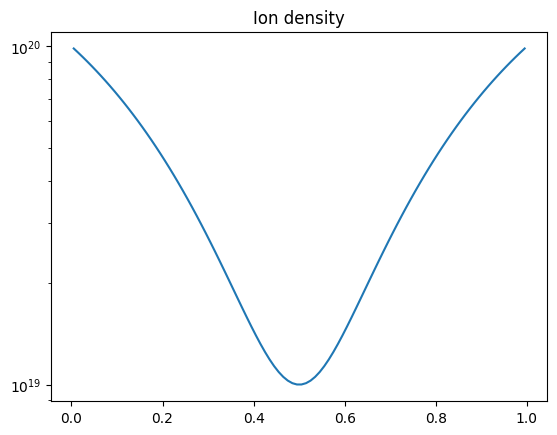

In [39]:
# Define the problem parameters
import numpy as np
import matplotlib.pyplot as plt
import math


n_cells = 100

t_final = 3.0e-5

x = np.linspace(0, 1, n_cells+1)
x_center = 0.5 * (x[:-1] + x[1:])
h = x[1] - x[0]

x0 = 0.5

ion_density = 1.0e20 - 9.0e19 * np.sin(math.pi * x_center)
# ion_density = 1.0e19+ 0.0 * x_center

ion_velocity = np.zeros(n_cells)

ion_temperature = np.zeros(n_cells)
ion_temperature[:] = 1.0

def get_index(x):
    return int(x * n_cells)

def get_BGK_stddev(T):
    return np.sqrt(T * 1.602176634e-19 / 1.67e-27)

def get_collision_rate(T, dens):
    return 3.2e-15 * np.sqrt(T/0.026) * dens

plt.figure()
plt.semilogy(x_center, ion_density)
plt.title('Ion density')

In [40]:
# Velocity-jump simulation

## Calculate reference solution using eigrene

import subprocess
import json

config = {}

config["mesh"] = {
    "type": "voxel",
    "Lx": 1,
    "Ly": 1,
    "Lz": 1,
    "nx": n_cells,
    "ny": 1,
    "nz": 1,
}

config["background"] = {
    "plasma_dens": ion_density.tolist(),
    "plasma_temp": ion_temperature.tolist(),
    "plasma_vel_x": ion_velocity.tolist(),
    "plasma_vel_y": np.zeros(n_cells, dtype=np.float64).tolist(),
    "plasma_vel_z": np.zeros(n_cells, dtype=np.float64).tolist(),
}

x0_index = get_index(x0)
bgk_stddev = get_BGK_stddev(ion_temperature[x0_index])
x0_velocity = ion_velocity[x0_index]
config["sources"] = [
    {
        "type": "point",
        "n_particles": 1000000,
        "intensity": 1.0,
        "pos": [x0, 0.5, 0.5],
        "vel_mean": [x0_velocity, 0, 0],
        "vel_stddev": bgk_stddev,
    },
]

config["boundary_conditions"] = [
    "reflective",
    "reflective",
    "reflective",
    "reflective",
    "reflective",
    "reflective",
]

config["t_final"] = t_final
config["max_steps"] = 10000000
config["seed"] = 0


inputstring = json.dumps(config)

with open("input.json", "w") as f:
    f.write(inputstring)

subprocess.check_output(["../build/main_json"]).decode("utf-8")

with open("output.json", "r") as f:
    outputstring = f.read()

output = json.loads(outputstring)

stats = output["stats"]
print(stats)

density_vj = np.array(output["density"])

{'grid_building_time': 2.1224e-05, 'num_collisions': 7810907, 'num_crossings': 22800692, 'total_time': 0.9854675580000001, 'trace_time': 0.985446334}


In [ ]:
# Simulate brownian motion with large timestep


n_particles = 100000
density_bm = np.zeros(n_cells, dtype=float)
h = 1/n_cells
dt_bm = t_final

for i in range(n_particles):
    x_particle = x0
    x_index = get_index(x_particle)
    t = 0
    v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))

    while t < t_final:
        # Calculate the collision rate
        collision_rate = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
        bgk_stddev = get_BGK_stddev(ion_temperature[x_index])        
        mu = ion_velocity[x_index]
        
        # update particle position
        meanx = x_particle + mu * dt_bm + (v - mu) / collision_rate * (1 - np.exp(-collision_rate * dt_bm))
        varx = 2*bgk_stddev**2/collision_rate**2 * (collision_rate*dt_bm - 2*(1-np.exp(-collision_rate*dt_bm)) + 0.5*(1 - np.exp(-2*collision_rate*dt_bm)))
        n = np.random.normal()
        x_particle = meanx + np.sqrt(varx) * n

        
        while True:
            if x_particle >= 1:
                x_particle = 2 - x_particle
                v = -v
            elif x_particle < 0:
                x_particle = -x_particle
                v = -v
            else:
                break
        x_index = get_index(x_particle)

        bgk_stddev = get_BGK_stddev(ion_temperature[x_index])        
        v = mu + bgk_stddev * np.random.normal()

        t += dt_bm




    # tally final position
    volume = 1/(n_cells)
    density_bm[x_index] += 1/volume / n_particles

In [49]:
# Simulate brownian motion with small timestep


n_particles = 100000
density_bm2 = np.zeros(n_cells, dtype=float)
h = 1/n_cells
dt_bm = 1.0e-6

for i in range(n_particles):
    x_particle = x0
    x_index = get_index(x_particle)
    t = 0
    v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))

    while t < t_final:
        # Calculate the collision rate
        collision_rate = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
        bgk_stddev = get_BGK_stddev(ion_temperature[x_index])        
        mu = ion_velocity[x_index]
        Dv = collision_rate * bgk_stddev**2

        
        # update particle position
        meanx = x_particle + mu * dt_bm + (v - mu) / collision_rate * (1 - np.exp(-collision_rate * dt_bm))
        # varx = 2*bgk_stddev**2/collision_rate**2 * (collision_rate*dt_bm - 2*(1-np.exp(-collision_rate*dt_bm)) + 0.5*(1 - np.exp(-2*collision_rate*dt_bm)))
        # varx = 2 * bgk_stddev**2 / collision_rate**2 * (2 * (np.exp(-collision_rate * dt_bm) - 1) + collision_rate * dt_bm * (1 + np.exp(-collision_rate * dt_bm)))

        varx = 2*Dv/collision_rate**3 * (collision_rate*dt_bm - 2*(1-np.exp(-collision_rate*dt_bm)) + 0.5*(1 - np.exp(-2*collision_rate*dt_bm)))
        n = np.random.normal()
        x_particle = meanx + np.sqrt(varx) * n

        
        while True:
            if x_particle >= 1:
                x_particle = 2 - x_particle
                v = -v
            elif x_particle < 0:
                x_particle = -x_particle
                v = -v
            else:
                break
        x_index = get_index(x_particle)

        bgk_stddev = get_BGK_stddev(ion_temperature[x_index])        
        v = mu + bgk_stddev * np.random.normal()


        t += dt_bm




    # tally final position
    volume = 1/(n_cells)
    density_bm2[x_index] += 1/volume / n_particles

In [43]:
# Simulate using underdamped langevin using full timestep

n_particles = 100000
density_lv = np.zeros(n_cells, dtype=float)
h = 1/n_cells
dt_lv = t_final

for i in range(n_particles):
    x_particle = x0
    x_index = get_index(x_particle)
    t = 0
    v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))

    while t < t_final:
        # Calculate the collision rate
        collision_rate = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
        bgk_stddev = get_BGK_stddev(ion_temperature[x_index])

        mu = ion_velocity[x_index]
        D = bgk_stddev**2 / collision_rate
        gamma = collision_rate
        Dv = collision_rate * bgk_stddev**2

        # update particle position using standard euler maruyama
        # x_particle = x_particle + v * dt_lv
        # v = v + gamma * (mu - v) * dt_lv + np.sqrt(2 * Dv * dt_lv) * np.random.normal()

        # use smarter update step by integrating the SDE assuming constant parameters
        # x_particle = x_particle + v * (1 - np.exp(-gamma * dt_lv)) / gamma + mu * (dt_lv - (1 - np.exp(-gamma * dt_lv)) / gamma) + np.sqrt(2*Dv) / gamma * np.sqrt(dt_lv + 1/(2*gamma)*(np.exp(-2*gamma*dt_lv)-1)) * np.random.normal()
        # x_particle = x_particle + mu * dt_lv + (v - mu) * (1 - np.exp(-gamma * dt_lv)) / gamma + np.sqrt(2*Dv/gamma**3 * (gamma*dt_lv - 2*(1-np.exp(-gamma*dt_lv)) + 0.5*(1 - np.exp(-2*gamma*dt_lv))) ) * np.random.normal()
        # v = v * np.exp(-gamma * dt_lv) + mu * (1 - np.exp(-gamma * dt_lv)) + np.sqrt(Dv / gamma) * np.sqrt(1 - np.exp(-2 * gamma * dt_lv)) * np.random.normal()
        n1 = np.random.normal()
        n2 = np.random.normal()
        meanv = v * np.exp(-gamma * dt_lv) + mu * (1 - np.exp(-gamma * dt_lv))
        varv = Dv / gamma * (1 - np.exp(-2 * gamma * dt_lv))
        meanx = x_particle + mu * dt_lv + (v - mu) * (1 - np.exp(-gamma * dt_lv)) / gamma
        varx = 2*Dv/gamma**3 * (gamma*dt_lv - 2*(1-np.exp(-gamma*dt_lv)) + 0.5*(1 - np.exp(-2*gamma*dt_lv)))
        covxv = (Dv/(gamma**2) * (1 - 2 * np.exp(-gamma*dt_lv) + np.exp(-2*gamma*dt_lv)))
        v = meanv + np.sqrt(varv) * n1
        x_particle = meanx + covxv/np.sqrt(varv) * n1 + np.sqrt(varx - covxv**2/varv) * n2

        while True:
            if x_particle >= 1:
                x_particle = 2 - x_particle
                v = -v
            elif x_particle < 0:
                x_particle = -x_particle
                v = -v
            else:
                break
        x_index = get_index(x_particle)

        t += dt_lv




    # tally final position
    volume = 1/(n_cells)
    density_lv[x_index] += 1/volume / n_particles

In [44]:
# Simulate using underdamped langevin with smaller timestep

n_particles = 100000
density_lv2 = np.zeros(n_cells, dtype=float)
h = 1/n_cells

for i in range(n_particles):
    x_particle = x0
    x_index = get_index(x_particle)
    t = 0
    v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))

    dt_lv = 1.0e-6
    while t < t_final:
        # Calculate the collision rate
        collision_rate = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
        bgk_stddev = get_BGK_stddev(ion_temperature[x_index])

        mu = ion_velocity[x_index]
        D = bgk_stddev**2 / collision_rate
        gamma = collision_rate
        Dv = collision_rate * bgk_stddev**2

        # dt_lv = 0.5 / collision_rate
        dt_lv = min(dt_lv, t_final - t)

        # update particle position using standard euler maruyama
        # x_particle = x_particle + v * dt_lv
        # v = v + gamma * (mu - v) * dt_lv + np.sqrt(2 * Dv * dt_lv) * np.random.normal()

        # use smarter update step by integrating the SDE assuming constant parameters
        # x_particle = x_particle + v * (1 - np.exp(-gamma * dt_lv)) / gamma + mu * (dt_lv - (1 - np.exp(-gamma * dt_lv)) / gamma) + np.sqrt(2*Dv) / gamma * np.sqrt(dt_lv + 1/(2*gamma)*(np.exp(-2*gamma*dt_lv)-1)) * np.random.normal()
        n1 = np.random.normal()
        n2 = np.random.normal()
        meanv = v * np.exp(-gamma * dt_lv) + mu * (1 - np.exp(-gamma * dt_lv))
        varv = Dv / gamma * (1 - np.exp(-2 * gamma * dt_lv))
        meanx = x_particle + mu * dt_lv + (v - mu) * (1 - np.exp(-gamma * dt_lv)) / gamma
        varx = 2*Dv/gamma**3 * (gamma*dt_lv - 2*(1-np.exp(-gamma*dt_lv)) + 0.5*(1 - np.exp(-2*gamma*dt_lv)))
        covxv = (Dv/(gamma**2) * (1 - 2 * np.exp(-gamma*dt_lv) + np.exp(-2*gamma*dt_lv)))
        v = meanv + np.sqrt(varv) * n1
        x_particle = meanx + covxv/np.sqrt(varv) * n1 + np.sqrt(varx - covxv**2/varv) * n2

        if x_particle >= 1:
            x_particle = 2 - x_particle
            v = -v
        elif x_particle < 0:
            x_particle = -x_particle
            v = -v
        x_index = get_index(x_particle)

        # use BAOAB to update particle position and velocity
        # B
        # v = v + gamma * (mu - v) * dt_lv * 0.5 + np.sqrt(Dv * dt_lv) * np.random.normal()
        # # A
        # x_particle = x_particle + v * dt_lv
        # if x_particle >= 1:
        #     x_particle = 2 - x_particle
        #     v = -v
        # elif x_particle < 0:
        #     x_particle = -x_particle
        #     v = -v
        # x_index = get_index(x_particle)
        # # Final B
        # collision_rate = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
        # bgk_stddev = get_BGK_stddev(ion_temperature[x_index])
        # mu = ion_velocity[x_index]
        # D = bgk_stddev**2 / collision_rate
        # gamma = collision_rate
        # Dv = collision_rate * bgk_stddev**2
        # v = v + gamma * (mu - v) * dt_lv * 0.5 + np.sqrt(Dv * dt_lv) * np.random.normal()

        # even better?, use BAOAB with the analytical expression
        # v = v * np.exp(-gamma * dt_lv * 0.5) + mu * (1 - np.exp(-gamma * dt_lv * 0.5)) + np.sqrt(Dv / gamma) * np.sqrt(1 - np.exp(-gamma * dt_lv)) * np.random.normal()
        # # x_particle = x_particle + v * dt_lv
        # x_particle = x_particle + v * (1 - np.exp(-gamma * dt_lv)) / gamma + mu * (dt_lv - (1 - np.exp(-gamma * dt_lv)) / gamma) + np.sqrt(2*Dv) / gamma * np.sqrt(dt_lv + 1/(2*gamma)*(np.exp(-2*gamma*dt_lv)-1)) * np.random.normal()
        # if x_particle >= 1:
        #     x_particle = 2 - x_particle
        #     v = -v
        # elif x_particle < 0:
        #     x_particle = -x_particle
        #     v = -v
        # x_index = get_index(x_particle)
        # collision_rate = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
        # bgk_stddev = get_BGK_stddev(ion_temperature[x_index])
        # mu = ion_velocity[x_index]
        # D = bgk_stddev**2 / collision_rate
        # gamma = collision_rate
        # Dv = collision_rate * bgk_stddev**2
        # v = v * np.exp(-gamma * dt_lv * 0.5) + mu * (1 - np.exp(-gamma * dt_lv * 0.5)) + np.sqrt(Dv / gamma) * np.sqrt(1 - np.exp(-gamma * dt_lv)) * np.random.normal()
       
        

        t += dt_lv




    # tally final position
    volume = 1/(n_cells)
    density_lv2[x_index] += 1/volume / n_particles

Text(0.5, 1.0, 'Density profile at t = 3.00e-05 s')

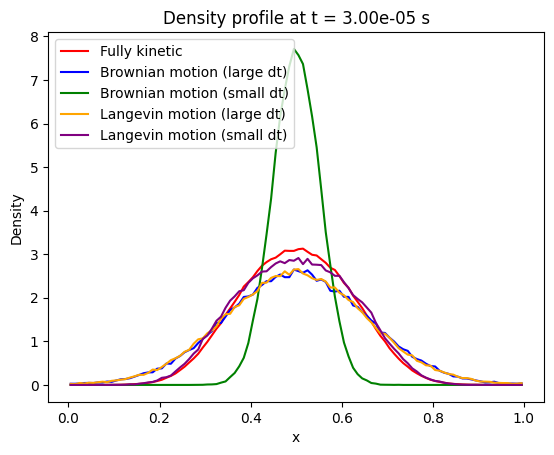

In [50]:
plt.figure()
plt.plot(x_center, density_vj, label='Fully kinetic', color='red')
plt.plot(x_center, density_bm, label='Brownian motion (large dt)', color='blue')
plt.plot(x_center, density_bm2, label='Brownian motion (small dt)', color='green')
plt.plot(x_center, density_lv, label='Langevin motion (large dt)', color='orange')
plt.plot(x_center, density_lv2, label='Langevin motion (small dt)', color='purple')
plt.legend()
plt.xlabel('x')
plt.ylabel('Density')
plt.title(f'Density profile at t = {t_final:.2e} s')